<a href="https://colab.research.google.com/github/ainainsofi/Cricket-Activity-Recognition/blob/master/MJ!.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# CELL 1 — INSTALL REQUIRED PACKAGES
# Major Project: Cricket Player Classification using HPE
# ============================================================

!pip install -q ultralytics roboflow pyyaml opencv-python matplotlib pandas numpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 102.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.0 MB/s eta 0:00:00


In [ ]:
# ============================================================
# CELL 2 — IMPORT LIBRARIES + CHECK GPU
# ============================================================

import os
import yaml
import json
import shutil
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from ultralytics import YOLO
from roboflow import Roboflow

import torch

print("=" * 70)
print("ENVIRONMENT CHECK")
print("=" * 70)

print("Ultralytics imported successfully")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ GPU is not available")

print("=" * 70)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ENVIRONMENT CHECK
Ultralytics imported successfully
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
# ============================================================
# CELL 3 — CONNECT TO NEW ROBOFLOW PROJECT
# ============================================================

from roboflow import Roboflow

# ------------------------------------------------------------
# ENTER YOUR NEW ROBOFLOW API KEY
# ------------------------------------------------------------

ROBOFLOW_API_KEY = "dSZNMUcwqVm4T9vkq4wN"

rf = Roboflow(api_key=ROBOFLOW_API_KEY)

# ------------------------------------------------------------
# ENTER YOUR NEW WORKSPACE AND PROJECT
# ------------------------------------------------------------

WORKSPACE = "ainain"
PROJECT = "cricket-annotations-lcuv3"

project = rf.workspace(WORKSPACE).project(PROJECT)

print("=" * 70)
print("ROBOFLOW PROJECT CONNECTION")
print("=" * 70)

print("Workspace :", WORKSPACE)
print("Project   :", PROJECT)
print("Project connected successfully!")

loading Roboflow workspace...
loading Roboflow project...
ROBOFLOW PROJECT CONNECTION
Workspace : ainain
Project   : cricket-annotations-lcuv3
Project connected successfully!


In [ ]:
# ============================================================
# CELL 4 — LIST AVAILABLE DATASET VERSIONS
# ============================================================

print("=" * 70)
print("AVAILABLE ROBOFLOW DATASET VERSIONS")
print("=" * 70)

versions = project.versions()

for v in versions:
    print(f"Version {v.version}: {v.name}")

AVAILABLE ROBOFLOW DATASET VERSIONS
Version 1: cricket annotations


In [ ]:
# ============================================================
# CELL 5 — DOWNLOAD VERSION 1 IN COCO FORMAT
# ============================================================

VERSION_NUMBER = 1

version = project.version(VERSION_NUMBER)

print("=" * 70)
print("SELECTED DATASET VERSION")
print("=" * 70)

print("Version:", VERSION_NUMBER)
print("Name:", version.name)

# Download COCO format
dataset = version.download(
    "coco",
    location="/content/cricket_major_coco"
)

print("\n" + "=" * 70)
print("DATASET DOWNLOAD COMPLETE")
print("=" * 70)
print("Location:", dataset.location)

SELECTED DATASET VERSION
Version: 1
Name: cricket annotations



Extracting Dataset Version Zip to /content/cricket_major_coco in coco:: 100%|██████████| 171/171 [00:00<00:00, 5253.90it/s]


DATASET DOWNLOAD COMPLETE
Location: /content/cricket_major_coco


In [ ]:
# ============================================================
# CELL 6 — INSPECT COCO DATASET STRUCTURE
# ============================================================

import os

COCO_ROOT = "/content/cricket_major_coco"

print("=" * 70)
print("COCO DATASET STRUCTURE")
print("=" * 70)

for root, dirs, files in os.walk(COCO_ROOT):

    level = root.replace(COCO_ROOT, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}  {file}")

COCO DATASET STRUCTURE
cricket_major_coco/
  README.roboflow.txt
  test/
    image_0025_jpg.rf.0d75f5cf215d5d29810cae2cbab39663.jpg
    image_0946_jpg.rf.014f66561f2441eab135f933986716e9.jpg
    _annotations.coco.json
    image_0375_jpg.rf.8051b53354bf67c1f9e9e35929445147.jpg
    image_0040_jpg.rf.b78e41e542e977056ec229ce7bf73c14.jpg
    image_0376_jpg.rf.1731697ef17982c60622578b14d38339.jpg
    image_0046_jpg.rf.2f3bcbf9847b5c2d2aed42920527cb38.jpg
    image_0046f-140-_jpg.rf.8b6afcc629d5297b4a73481d08a67e18.jpg
    image_0721_jpg.rf.97ed26a3079b578bee5db18a61a10e19.jpg
    image_0361_jpg.rf.8fa4128a78aff0cdf07a16663d86669b.jpg
    image_0043_jpg.rf.2f80e926b8baee03e95e4f1bf77fab71.jpg
    image_0356_jpg.rf.f8ee4ef3a5c0855ed898c825d058ea0a.jpg
    image_0046f-148-_jpg.rf.70e60892cb3efe7f3ac6af7d953b150a.jpg
    image_0005_jpg.rf.334dd1cf8bde092f93c1d3cf9fc6f667.jpg
    image_0018_jpg.rf.62a4fc617af346cbff21aa3cc71416cd.jpg
  train/
    image_1061_jpg.rf.a5d98ec04b4338a5e60be5ced852c6c

In [ ]:
# ============================================================
# CELL 7 — INSPECT KEYPOINT ORDER IN NEW COCO DATASET
# ============================================================

import json
import os

COCO_ROOT = "/content/cricket_major_coco"

# Use the training annotations as the primary source
ANNOTATION_FILE = os.path.join(
    COCO_ROOT,
    "train",
    "_annotations.coco.json"
)

print("=" * 70)
print("COCO KEYPOINT DEFINITION")
print("=" * 70)

with open(ANNOTATION_FILE, "r") as f:
    coco_data = json.load(f)

print("\nCategories:")
for category in coco_data["categories"]:
    print("\nCategory ID   :", category["id"])
    print("Category Name :", category["name"])

    if "keypoints" in category:
        print("\nNumber of keypoints:", len(category["keypoints"]))
        print("\nKeypoint order:")

        for idx, kp in enumerate(category["keypoints"]):
            print(f"{idx:2d} -> {kp}")

    if "skeleton" in category:
        print("\nSkeleton connections:")
        print(category["skeleton"])

print("\n" + "=" * 70)

COCO KEYPOINT DEFINITION

Categories:

Category ID   : 0
Category Name : cricket-annotations

Category ID   : 1
Category Name : Player

Number of keypoints: 17

Keypoint order:
 0 -> 6-right_shoulder
 1 -> 5-left_shoulder
 2 -> 8-right_elbow
 3 -> 10-right_wrist
 4 -> 7-left_elbow
 5 -> 9-left_wrist
 6 -> 12-right_hip
 7 -> 11-left_hip
 8 -> 13-left_knee
 9 -> 15-left_ankle
10 -> 14-right_knee
11 -> 16-right_ankle
12 -> 2-right_eye
13 -> 1-left_eye
14 -> 0-nose
15 -> 4-right_ear
16 -> 3-left_ear

Skeleton connections:
[[1, 3], [3, 4], [2, 5], [5, 6], [7, 8], [1, 2], [2, 8], [1, 7], [11, 12], [9, 10], [7, 11], [8, 9], [15, 14], [15, 13], [14, 17], [13, 16]]



In [ ]:
# ============================================================
# CELL 8 — VALIDATE COCO POSE ANNOTATIONS
# ============================================================

import json
import os
from collections import Counter

COCO_ROOT = "/content/cricket_major_coco"

splits = ["train", "valid", "test"]

print("=" * 70)
print("COCO ANNOTATION VALIDATION")
print("=" * 70)

for split in splits:

    annotation_file = os.path.join(
        COCO_ROOT,
        split,
        "_annotations.coco.json"
    )

    with open(annotation_file, "r") as f:
        data = json.load(f)

    categories = {
        c["id"]: c["name"]
        for c in data["categories"]
    }

    annotations = data["annotations"]

    category_counts = Counter(
        ann["category_id"]
        for ann in annotations
    )

    keypoint_counts = []

    for ann in annotations:
        if "keypoints" in ann:
            keypoint_counts.append(len(ann["keypoints"]))

    print(f"\n{'-' * 70}")
    print(f"SPLIT: {split.upper()}")
    print(f"{'-' * 70}")

    print("Images:", len(data["images"]))
    print("Annotations:", len(annotations))

    print("\nCategory usage:")
    for category_id, count in category_counts.items():
        print(
            f"  ID {category_id} "
            f"({categories.get(category_id, 'UNKNOWN')}): "
            f"{count}"
        )

    print("\nKeypoint annotation lengths:")

    if keypoint_counts:
        print("  Number of annotations with keypoints:",
              len(keypoint_counts))
        print("  Unique lengths:",
              sorted(set(keypoint_counts)))

        expected_length = 17 * 3

        if all(x == expected_length for x in keypoint_counts):
            print("  ✅ All keypoint arrays contain 17 × 3 values")
        else:
            print("  ⚠️ Some keypoint arrays do not contain 51 values")

    else:
        print("  ❌ No keypoint annotations found")

print("\n" + "=" * 70)
print("VALIDATION COMPLETE")
print("=" * 70)

COCO ANNOTATION VALIDATION

----------------------------------------------------------------------
SPLIT: TRAIN
----------------------------------------------------------------------
Images: 124
Annotations: 351

Category usage:
  ID 1 (Player): 351

Keypoint annotation lengths:
  Number of annotations with keypoints: 351
  Unique lengths: [51]
  ✅ All keypoint arrays contain 17 × 3 values

----------------------------------------------------------------------
SPLIT: VALID
----------------------------------------------------------------------
Images: 29
Annotations: 89

Category usage:
  ID 1 (Player): 89

Keypoint annotation lengths:
  Number of annotations with keypoints: 89
  Unique lengths: [51]
  ✅ All keypoint arrays contain 17 × 3 values

----------------------------------------------------------------------
SPLIT: TEST
----------------------------------------------------------------------
Images: 14
Annotations: 49

Category usage:
  ID 1 (Player): 49

Keypoint annotation lengt

In [ ]:
# ============================================================
# CELL 9 — COCO → CORRECTED YOLO POSE CONVERSION
# ============================================================

import os
import json
import shutil
import numpy as np

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

COCO_ROOT = "/content/cricket_major_coco"
YOLO_ROOT = "/content/cricket_major_yolo"

# Remove previous conversion if it exists
if os.path.exists(YOLO_ROOT):
    shutil.rmtree(YOLO_ROOT)

# ------------------------------------------------------------
# KEYPOINT REORDER
# Roboflow COCO order → Standard COCO / YOLO order
# ------------------------------------------------------------

reorder = [
    14, 13, 12, 16, 15,
    1, 0, 4, 2, 5, 3,
    7, 6, 8, 10, 9, 11
]

# Standard COCO / YOLO keypoint names
keypoint_names = [
    "nose",
    "left_eye",
    "right_eye",
    "left_ear",
    "right_ear",
    "left_shoulder",
    "right_shoulder",
    "left_elbow",
    "right_elbow",
    "left_wrist",
    "right_wrist",
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_ankle",
    "right_ankle"
]

splits = ["train", "valid", "test"]

print("=" * 70)
print("COCO → YOLO POSE CONVERSION")
print("=" * 70)

# ------------------------------------------------------------
# CONVERSION FUNCTION
# ------------------------------------------------------------

def convert_split(split):

    coco_dir = os.path.join(COCO_ROOT, split)
    json_file = os.path.join(coco_dir, "_annotations.coco.json")

    image_out = os.path.join(YOLO_ROOT, split, "images")
    label_out = os.path.join(YOLO_ROOT, split, "labels")

    os.makedirs(image_out, exist_ok=True)
    os.makedirs(label_out, exist_ok=True)

    with open(json_file, "r") as f:
        coco = json.load(f)

    # Map image ID → image information
    image_info = {
        img["id"]: img
        for img in coco["images"]
    }

    # Group annotations by image
    annotations_by_image = {}

    for ann in coco["annotations"]:

        image_id = ann["image_id"]

        if image_id not in annotations_by_image:
            annotations_by_image[image_id] = []

        annotations_by_image[image_id].append(ann)

    converted_images = 0
    converted_annotations = 0

    # --------------------------------------------------------
    # PROCESS EACH IMAGE
    # --------------------------------------------------------

    for image_id, img in image_info.items():

        filename = img["file_name"]

        width = img["width"]
        height = img["height"]

        source_image = os.path.join(coco_dir, filename)

        # Copy image
        destination_image = os.path.join(
            image_out,
            filename
        )

        shutil.copy2(
            source_image,
            destination_image
        )

        label_lines = []

        # ----------------------------------------------------
        # PROCESS ANNOTATIONS
        # ----------------------------------------------------

        for ann in annotations_by_image.get(image_id, []):

            # Only Player category
            if ann["category_id"] != 1:
                continue

            bbox = ann["bbox"]

            x, y, w, h = bbox

            # COCO bbox → YOLO normalized bbox
            x_center = (x + w / 2) / width
            y_center = (y + h / 2) / height

            w_norm = w / width
            h_norm = h / height

            # ------------------------------------------------
            # KEYPOINTS
            # ------------------------------------------------

            original_kps = ann["keypoints"]

            # Convert flat list into:
            # [[x,y,v], [x,y,v], ...]
            original_kps = np.array(
                original_kps,
                dtype=float
            ).reshape(17, 3)

            # Apply verified reorder
            corrected_kps = original_kps[reorder]

            # Normalize x/y coordinates
            corrected_kps[:, 0] /= width
            corrected_kps[:, 1] /= height

            # Flatten
            keypoint_values = corrected_kps.flatten()

            # ------------------------------------------------
            # YOLO POSE LABEL
            # ------------------------------------------------

            values = [
                0,              # Player class
                x_center,
                y_center,
                w_norm,
                h_norm
            ]

            values.extend(keypoint_values.tolist())

            label_line = " ".join(
                f"{value:.6f}"
                for value in values
            )

            label_lines.append(label_line)

            converted_annotations += 1

        # ----------------------------------------------------
        # WRITE LABEL FILE
        # ----------------------------------------------------

        label_filename = os.path.splitext(filename)[0] + ".txt"

        label_file = os.path.join(
            label_out,
            label_filename
        )

        with open(label_file, "w") as f:
            f.write("\n".join(label_lines))

        converted_images += 1

    return converted_images, converted_annotations


# ------------------------------------------------------------
# CONVERT ALL SPLITS
# ------------------------------------------------------------

results = {}

for split in splits:

    images, annotations = convert_split(split)

    results[split] = {
        "images": images,
        "annotations": annotations
    }

    print(
        f"{split.upper():<6} → "
        f"{images} images, "
        f"{annotations} annotations"
    )

# ------------------------------------------------------------
# CREATE YOLO DATASET YAML
# ------------------------------------------------------------

yaml_content = """path: /content/cricket_major_yolo

train: train/images
val: valid/images
test: test/images

nc: 1
names:
  0: Player

kpt_shape: [17, 3]

flip_idx: [
  0, 2, 1, 4, 3,
  6, 5, 8, 7, 10, 9,
  12, 11, 14, 13, 16, 15
]
"""

yaml_file = os.path.join(
    YOLO_ROOT,
    "data.yaml"
)

with open(yaml_file, "w") as f:
    f.write(yaml_content)

# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CONVERSION COMPLETE")
print("=" * 70)

for split, result in results.items():
    print(
        f"{split.upper():<6}: "
        f"{result['images']} images | "
        f"{result['annotations']} annotations"
    )

print("\nYOLO dataset:")
print(YOLO_ROOT)

print("\nYAML:")
print(yaml_file)

print("\nKeypoint order:")
for i, name in enumerate(keypoint_names):
    print(f"{i:2d} → {name}")

print("=" * 70)

COCO → YOLO POSE CONVERSION
TRAIN  → 124 images, 351 annotations
VALID  → 29 images, 89 annotations
TEST   → 14 images, 49 annotations

CONVERSION COMPLETE
TRAIN : 124 images | 351 annotations
VALID : 29 images | 89 annotations
TEST  : 14 images | 49 annotations

YOLO dataset:
/content/cricket_major_yolo

YAML:
/content/cricket_major_yolo/data.yaml

Keypoint order:
 0 → nose
 1 → left_eye
 2 → right_eye
 3 → left_ear
 4 → right_ear
 5 → left_shoulder
 6 → right_shoulder
 7 → left_elbow
 8 → right_elbow
 9 → left_wrist
10 → right_wrist
11 → left_hip
12 → right_hip
13 → left_knee
14 → right_knee
15 → left_ankle
16 → right_ankle


VISUAL VERIFICATION
Image: image_0351_jpg.rf.ec6c5147ffe4271656532502a5b89325.jpg
Label: image_0351_jpg.rf.ec6c5147ffe4271656532502a5b89325.txt
Number of Player annotations: 1


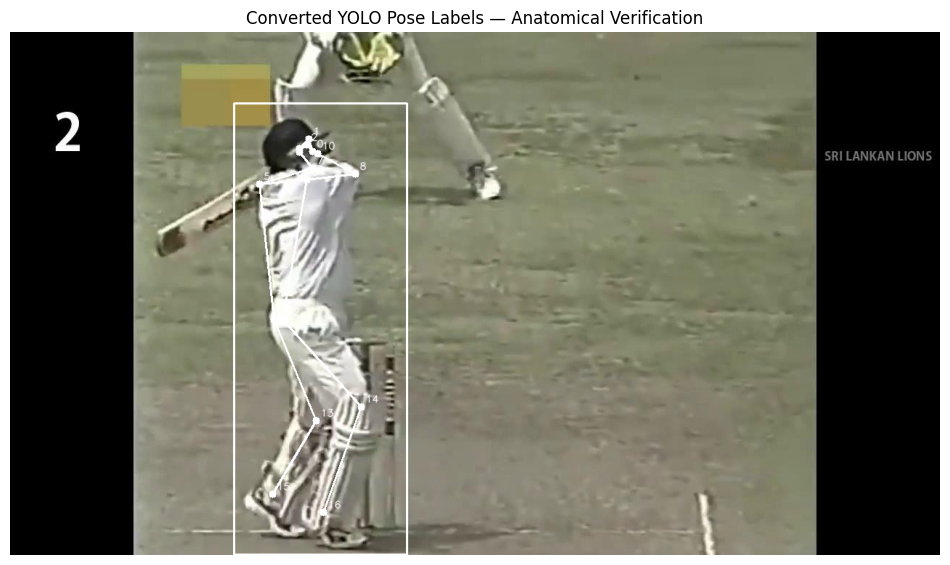


Keypoint numbering:
 0 → nose
 1 → left_eye
 2 → right_eye
 3 → left_ear
 4 → right_ear
 5 → left_shoulder
 6 → right_shoulder
 7 → left_elbow
 8 → right_elbow
 9 → left_wrist
10 → right_wrist
11 → left_hip
12 → right_hip
13 → left_knee
14 → right_knee
15 → left_ankle
16 → right_ankle

VISUAL CHECK COMPLETE


In [ ]:
# ============================================================
# CELL 10 — VISUAL CHECK OF CONVERTED YOLO POSE LABELS
# ============================================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

YOLO_ROOT = "/content/cricket_major_yolo"

# ------------------------------------------------------------
# STANDARD COCO KEYPOINT NAMES
# ------------------------------------------------------------

keypoint_names = [
    "nose",
    "left_eye",
    "right_eye",
    "left_ear",
    "right_ear",
    "left_shoulder",
    "right_shoulder",
    "left_elbow",
    "right_elbow",
    "left_wrist",
    "right_wrist",
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_ankle",
    "right_ankle"
]

# Standard COCO skeleton
skeleton = [
    (0, 1), (0, 2),
    (1, 3), (2, 4),
    (5, 6),
    (5, 7), (7, 9),
    (6, 8), (8, 10),
    (5, 11), (6, 12),
    (11, 12),
    (11, 13), (13, 15),
    (12, 14), (14, 16)
]

# ------------------------------------------------------------
# SELECT ONE IMAGE
# ------------------------------------------------------------

image_dir = os.path.join(
    YOLO_ROOT,
    "train",
    "images"
)

label_dir = os.path.join(
    YOLO_ROOT,
    "train",
    "labels"
)

images = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

# Use image_0351 if available because we inspected
# this image previously.
preferred = [
    f for f in images
    if "0351" in f
]

if preferred:
    image_name = preferred[0]
else:
    image_name = images[0]

image_path = os.path.join(
    image_dir,
    image_name
)

label_path = os.path.join(
    label_dir,
    os.path.splitext(image_name)[0] + ".txt"
)

print("=" * 70)
print("VISUAL VERIFICATION")
print("=" * 70)

print("Image:", image_name)
print("Label:", os.path.basename(label_path))

# ------------------------------------------------------------
# LOAD IMAGE
# ------------------------------------------------------------

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(
        f"Could not read image: {image_path}"
    )

image = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

height, width = image.shape[:2]

# ------------------------------------------------------------
# READ YOLO LABEL
# ------------------------------------------------------------

with open(label_path, "r") as f:
    lines = [
        line.strip()
        for line in f
        if line.strip()
    ]

print("Number of Player annotations:", len(lines))

# ------------------------------------------------------------
# DRAW EACH PLAYER
# ------------------------------------------------------------

output = image.copy()

for line in lines:

    values = list(
        map(float, line.split())
    )

    # YOLO:
    # class + bbox(4) + 17*(x,y,visibility)
    if len(values) != 5 + 17 * 3:
        print(
            "⚠️ Unexpected label length:",
            len(values)
        )
        continue

    # --------------------------------------------------------
    # BOUNDING BOX
    # --------------------------------------------------------

    _, xc, yc, bw, bh = values[:5]

    x1 = int((xc - bw / 2) * width)
    y1 = int((yc - bh / 2) * height)
    x2 = int((xc + bw / 2) * width)
    y2 = int((yc + bh / 2) * height)

    cv2.rectangle(
        output,
        (x1, y1),
        (x2, y2),
        (255, 255, 255),
        2
    )

    # --------------------------------------------------------
    # KEYPOINTS
    # --------------------------------------------------------

    kp_values = np.array(
        values[5:],
        dtype=float
    ).reshape(17, 3)

    points = []

    for i, (x, y, v) in enumerate(kp_values):

        px = int(x * width)
        py = int(y * height)

        points.append((px, py, v))

        # Draw visible/labeled keypoints
        if v > 0:

            cv2.circle(
                output,
                (px, py),
                5,
                (255, 255, 255),
                -1
            )

            # Label keypoint number
            cv2.putText(
                output,
                str(i),
                (px + 6, py - 6),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45,
                (255, 255, 255),
                1,
                cv2.LINE_AA
            )

    # --------------------------------------------------------
    # DRAW SKELETON
    # --------------------------------------------------------

    for a, b in skeleton:

        x1, y1, v1 = points[a]
        x2, y2, v2 = points[b]

        if v1 > 0 and v2 > 0:

            cv2.line(
                output,
                (x1, y1),
                (x2, y2),
                (255, 255, 255),
                2
            )

# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

plt.figure(figsize=(12, 10))
plt.imshow(output)
plt.axis("off")
plt.title(
    "Converted YOLO Pose Labels — Anatomical Verification"
)
plt.show()

print("\nKeypoint numbering:")
for i, name in enumerate(keypoint_names):
    print(f"{i:2d} → {name}")

print("\n" + "=" * 70)
print("VISUAL CHECK COMPLETE")
print("=" * 70)

In [ ]:
# ============================================================
# CELL 11 — CORRECTED DATASET-WIDE YOLO POSE VALIDATION
# ============================================================

import os
import numpy as np

YOLO_ROOT = "/content/cricket_major_yolo"

splits = ["train", "valid", "test"]

EXPECTED_VALUES = 5 + (17 * 3)

print("=" * 70)
print("CORRECTED YOLO POSE LABEL VALIDATION")
print("=" * 70)

total_images = 0
total_annotations = 0
total_errors = 0

for split in splits:

    image_dir = os.path.join(
        YOLO_ROOT,
        split,
        "images"
    )

    label_dir = os.path.join(
        YOLO_ROOT,
        split,
        "labels"
    )

    image_files = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    split_annotations = 0
    split_errors = 0
    empty_labels = 0

    for image_name in image_files:

        label_name = (
            os.path.splitext(image_name)[0]
            + ".txt"
        )

        label_path = os.path.join(
            label_dir,
            label_name
        )

        total_images += 1

        # ----------------------------------------------------
        # CHECK LABEL EXISTS
        # ----------------------------------------------------

        if not os.path.exists(label_path):

            print(
                f"❌ Missing label: "
                f"{split}/{image_name}"
            )

            split_errors += 1
            continue

        with open(label_path, "r") as f:

            lines = [
                line.strip()
                for line in f
                if line.strip()
            ]

        # ----------------------------------------------------
        # EMPTY LABEL
        # ----------------------------------------------------

        if len(lines) == 0:

            empty_labels += 1
            continue

        # ----------------------------------------------------
        # CHECK EACH ANNOTATION
        # ----------------------------------------------------

        for line_number, line in enumerate(
            lines,
            start=1
        ):

            values = line.split()

            # ------------------------------------------------
            # EXPECTED NUMBER OF VALUES
            # ------------------------------------------------

            if len(values) != EXPECTED_VALUES:

                print(
                    f"❌ Wrong label length: "
                    f"{split}/{label_name} "
                    f"(line {line_number}: "
                    f"{len(values)} values)"
                )

                split_errors += 1
                continue

            values = np.array(
                values,
                dtype=float
            )

            # ------------------------------------------------
            # CLASS ID
            # ------------------------------------------------

            class_id = values[0]

            if class_id != 0:

                print(
                    f"❌ Invalid class ID: "
                    f"{split}/{label_name}"
                )

                split_errors += 1

            # ------------------------------------------------
            # BOUNDING BOX VALUES
            # ------------------------------------------------

            bbox = values[1:5]

            if np.any(bbox < 0) or np.any(bbox > 1):

                print(
                    f"❌ Invalid bounding box value: "
                    f"{split}/{label_name}"
                )

                split_errors += 1

            # ------------------------------------------------
            # KEYPOINTS
            # ------------------------------------------------

            keypoints = values[5:].reshape(
                17,
                3
            )

            x_coordinates = keypoints[:, 0]
            y_coordinates = keypoints[:, 1]
            visibility = keypoints[:, 2]

            # ------------------------------------------------
            # KEYPOINT X/Y
            # ------------------------------------------------

            if (
                np.any(x_coordinates < 0)
                or
                np.any(x_coordinates > 1)
                or
                np.any(y_coordinates < 0)
                or
                np.any(y_coordinates > 1)
            ):

                print(
                    f"❌ Keypoint coordinate outside [0,1]: "
                    f"{split}/{label_name}"
                )

                split_errors += 1

            # ------------------------------------------------
            # VISIBILITY
            # YOLO pose visibility:
            # 0 = not labeled
            # 1 = labeled but not visible
            # 2 = labeled and visible
            # ------------------------------------------------

            if not np.all(
                np.isin(
                    visibility,
                    [0, 1, 2]
                )
            ):

                print(
                    f"❌ Invalid visibility value: "
                    f"{split}/{label_name}"
                )

                split_errors += 1

            split_annotations += 1

    total_annotations += split_annotations
    total_errors += split_errors

    print("\n" + "-" * 70)
    print(f"{split.upper()}")
    print("-" * 70)

    print("Images           :", len(image_files))
    print("Annotations      :", split_annotations)
    print("Empty labels     :", empty_labels)
    print("Validation errors:", split_errors)

# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL VALIDATION")
print("=" * 70)

print("Total images      :", total_images)
print("Total annotations :", total_annotations)
print("Total errors      :", total_errors)

if total_errors == 0:

    print("\n✅ ALL YOLO POSE LABELS ARE VALID")
    print("✅ Dataset is ready for YOLOv8-Pose training")

else:

    print("\n⚠️ ERRORS FOUND — DO NOT TRAIN YET")

print("=" * 70)

CORRECTED YOLO POSE LABEL VALIDATION

----------------------------------------------------------------------
TRAIN
----------------------------------------------------------------------
Images           : 124
Annotations      : 351
Empty labels     : 0
Validation errors: 0

----------------------------------------------------------------------
VALID
----------------------------------------------------------------------
Images           : 29
Annotations      : 89
Empty labels     : 0
Validation errors: 0

----------------------------------------------------------------------
TEST
----------------------------------------------------------------------
Images           : 14
Annotations      : 49
Empty labels     : 0
Validation errors: 0

FINAL VALIDATION
Total images      : 167
Total annotations : 489
Total errors      : 0

✅ ALL YOLO POSE LABELS ARE VALID
✅ Dataset is ready for YOLOv8-Pose training


In [ ]:
# ============================================================
# CELL 12 — TRAIN YOLOv8n-Pose BASELINE
# ============================================================

from ultralytics import YOLO

MODEL_PATH = "yolov8n-pose.pt"
DATA_YAML = "/content/cricket_major_yolo/data.yaml"

model = YOLO(MODEL_PATH)

results = model.train(
    data=DATA_YAML,
    epochs=30,
    imgsz=512,
    batch=8,
    project="/content/cricket_major_yolo_training",
    name="yolov8n_pose_baseline",
    exist_ok=True
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cricket_major_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-pose.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_pose_baseline, nbs=64, nms=None, opset=No

In [ ]:
# ============================================================
# CELL 13 — FINAL TEST-SET EVALUATION
# ============================================================

from ultralytics import YOLO

BEST_MODEL = "/content/cricket_major_yolo_training/yolov8n_pose_baseline/weights/best.pt"
DATA_YAML = "/content/cricket_major_yolo/data.yaml"

model = YOLO(BEST_MODEL)

test_results = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=512,
    batch=8,
    project="/content/cricket_major_yolo_training",
    name="test_evaluation",
    exist_ok=True
)

print("\n" + "=" * 70)
print("TEST-SET POSE EVALUATION")
print("=" * 70)

print("Pose Precision   :", test_results.pose.p[0])
print("Pose Recall      :", test_results.pose.r[0])
print("Pose mAP50       :", test_results.pose.map50)
print("Pose mAP50-95    :", test_results.pose.map)
print("=" * 70)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-pose summary (fused): 81 layers, 3,289,964 parameters, 0 gradients, 9.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1574.2±373.9 MB/s, size: 60.3 KB)
val: Scanning /content/cricket_major_yolo/test/labels... 14 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14/14 1.1Kit/s 0.0s
val: New cache created: /content/cricket_major_yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.0it/s 1.0s
                   all         14         49          1      0.952      0.987      0.678      0.872      0.832      0.844      0.458
Speed: 1.9ms preprocess, 36.1ms inference, 0.0ms loss, 3.9ms postprocess per image
Results saved to /content/cricket_major_yolo_training/test_evaluation

TEST-SET POSE EVALUATION
Pose Precision   : 0.8716990555992975
Pose Recall      : 0.832

Number of test images: 14


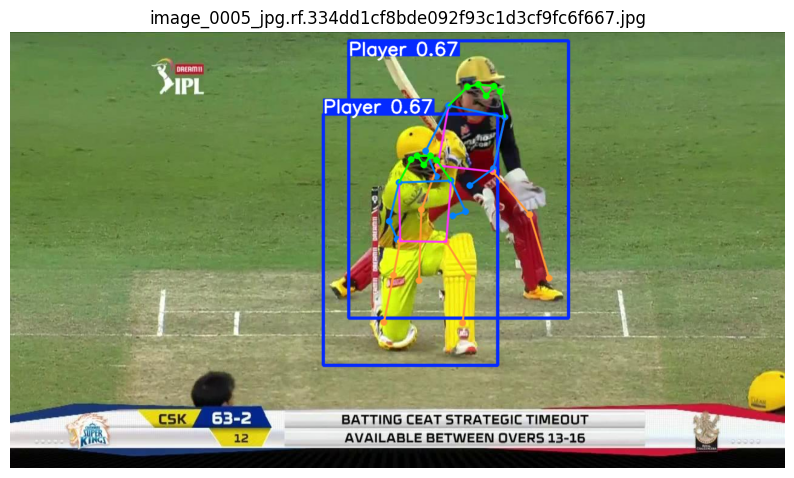

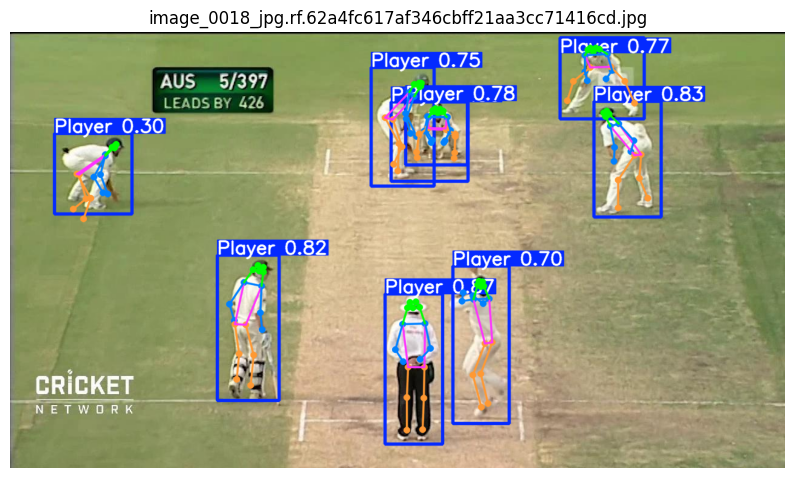

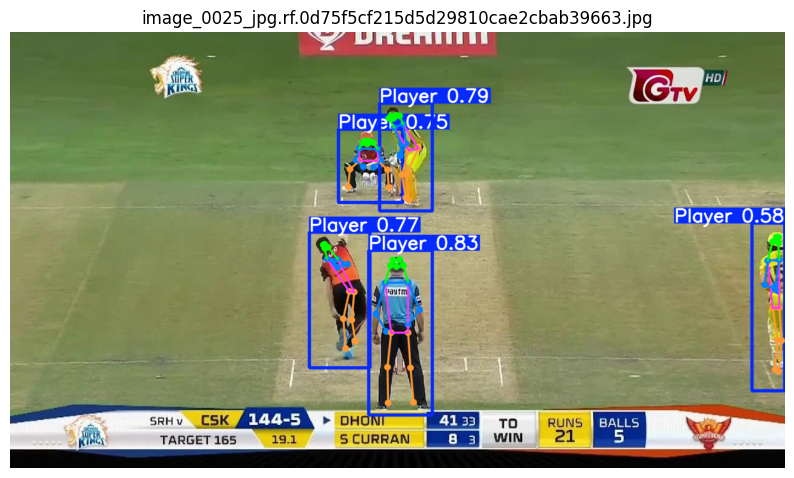

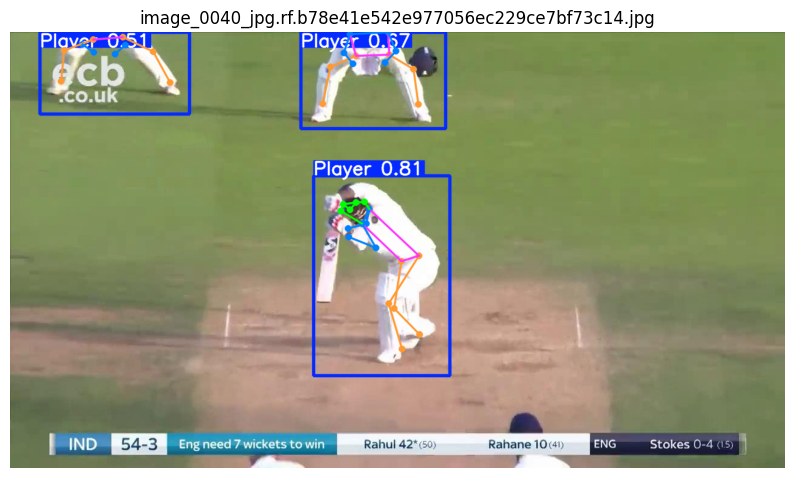

In [ ]:
# ============================================================
# CELL 14 — VISUALIZE YOLOv8-POSE PREDICTIONS ON TEST IMAGES
# ============================================================

from ultralytics import YOLO
import os
import matplotlib.pyplot as plt

BEST_MODEL = "/content/cricket_major_yolo_training/yolov8n_pose_baseline/weights/best.pt"
TEST_DIR = "/content/cricket_major_yolo/test/images"

model = YOLO(BEST_MODEL)

test_images = sorted([
    os.path.join(TEST_DIR, f)
    for f in os.listdir(TEST_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("Number of test images:", len(test_images))

# Select first 4 unseen test images
selected_images = test_images[:4]

for image_path in selected_images:

    results = model.predict(
        source=image_path,
        imgsz=512,
        conf=0.25,
        verbose=False
    )

    result = results[0]

    plotted = result.plot()

    plt.figure(figsize=(10, 7))
    plt.imshow(plotted[:, :, ::-1])
    plt.title(os.path.basename(image_path))
    plt.axis("off")
    plt.show()

In [ ]:
# ============================================================
# CELL 15 — CORRECTED QUANTITATIVE KEYPOINT ANALYSIS
# ============================================================

from ultralytics import YOLO
import os
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

BEST_MODEL = (
    "/content/cricket_major_yolo_training/"
    "yolov8n_pose_baseline/weights/best.pt"
)

TEST_IMAGE_DIR = "/content/cricket_major_yolo/test/images"
TEST_LABEL_DIR = "/content/cricket_major_yolo/test/labels"

# ------------------------------------------------------------
# LOAD MODEL
# ------------------------------------------------------------

model = YOLO(BEST_MODEL)

KEYPOINT_NAMES = [
    "nose",
    "left_eye",
    "right_eye",
    "left_ear",
    "right_ear",
    "left_shoulder",
    "right_shoulder",
    "left_elbow",
    "right_elbow",
    "left_wrist",
    "right_wrist",
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_ankle",
    "right_ankle"
]

# ------------------------------------------------------------
# IoU FUNCTION
# ------------------------------------------------------------

def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = (
        max(0, x2 - x1) *
        max(0, y2 - y1)
    )

    area1 = (
        max(0, box1[2] - box1[0]) *
        max(0, box1[3] - box1[1])
    )

    area2 = (
        max(0, box2[2] - box2[0]) *
        max(0, box2[3] - box2[1])
    )

    union = area1 + area2 - intersection

    if union <= 0:
        return 0.0

    return intersection / union


# ------------------------------------------------------------
# STORAGE
# ------------------------------------------------------------

all_nme = []

per_keypoint_errors = {
    name: []
    for name in KEYPOINT_NAMES
}

threshold_005 = []
threshold_010 = []
threshold_020 = []

matched_players = 0
missed_players = 0
total_gt_players = 0

# ------------------------------------------------------------
# TEST IMAGES
# ------------------------------------------------------------

test_images = sorted([
    f for f in os.listdir(TEST_IMAGE_DIR)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
])

print("=" * 75)
print("CORRECTED QUANTITATIVE KEYPOINT LOCALIZATION ANALYSIS")
print("=" * 75)

# ------------------------------------------------------------
# PROCESS EACH IMAGE
# ------------------------------------------------------------

for image_name in test_images:

    image_path = os.path.join(
        TEST_IMAGE_DIR,
        image_name
    )

    label_path = os.path.join(
        TEST_LABEL_DIR,
        os.path.splitext(image_name)[0] + ".txt"
    )

    # --------------------------------------------------------
    # READ GROUND TRUTH
    # --------------------------------------------------------

    gt_boxes = []
    gt_keypoints = []
    gt_visibility = []

    with open(label_path, "r") as f:

        lines = [
            line.strip()
            for line in f
            if line.strip()
        ]

    for line in lines:

        values = np.array(
            line.split(),
            dtype=float
        )

        # YOLO format:
        # class
        # bbox = xc yc width height
        # keypoints = x y visibility

        xc, yc, w, h = values[1:5]

        gt_box = np.array([
            xc - w / 2,
            yc - h / 2,
            xc + w / 2,
            yc + h / 2
        ])

        keypoints = values[5:].reshape(
            17,
            3
        )

        gt_boxes.append(gt_box)

        gt_keypoints.append(
            keypoints[:, :2]
        )

        gt_visibility.append(
            keypoints[:, 2]
        )

    gt_boxes = np.array(gt_boxes)
    gt_keypoints = np.array(gt_keypoints)
    gt_visibility = np.array(gt_visibility)

    total_gt_players += len(gt_boxes)

    # --------------------------------------------------------
    # YOLO PREDICTION
    # --------------------------------------------------------

    results = model.predict(
        source=image_path,
        imgsz=512,
        conf=0.25,
        verbose=False
    )

    result = results[0]

    if (
        result.boxes is None
        or len(result.boxes) == 0
    ):

        missed_players += len(gt_boxes)
        continue

    # IMPORTANT:
    # xyxyn = normalized coordinates [0,1]
    pred_boxes = (
        result.boxes.xyxyn
        .cpu()
        .numpy()
    )

    # Keypoints are also normalized
    pred_keypoints = (
        result.keypoints.xyn
        .cpu()
        .numpy()
    )

    used_predictions = set()

    # --------------------------------------------------------
    # MATCH EACH GT PLAYER
    # --------------------------------------------------------

    for gt_index in range(len(gt_boxes)):

        best_iou = 0.0
        best_prediction = None

        for pred_index in range(len(pred_boxes)):

            if pred_index in used_predictions:
                continue

            iou = calculate_iou(
                gt_boxes[gt_index],
                pred_boxes[pred_index]
            )

            if iou > best_iou:

                best_iou = iou
                best_prediction = pred_index

        # ----------------------------------------------------
        # MATCH THRESHOLD
        # ----------------------------------------------------

        if (
            best_prediction is None
            or best_iou < 0.50
        ):

            missed_players += 1
            continue

        used_predictions.add(best_prediction)

        matched_players += 1

        gt_kpts = gt_keypoints[gt_index]
        pred_kpts = pred_keypoints[best_prediction]

        visibility = gt_visibility[gt_index]

        # ----------------------------------------------------
        # NORMALIZATION SCALE
        # Use GT bounding-box diagonal
        # ----------------------------------------------------

        gt_box = gt_boxes[gt_index]

        box_width = (
            gt_box[2] - gt_box[0]
        )

        box_height = (
            gt_box[3] - gt_box[1]
        )

        box_diagonal = np.sqrt(
            box_width ** 2 +
            box_height ** 2
        )

        if box_diagonal <= 0:
            continue

        # ----------------------------------------------------
        # KEYPOINT ERROR
        # ----------------------------------------------------

        for k in range(17):

            # Visibility 0 = not labeled
            if visibility[k] == 0:
                continue

            distance = np.linalg.norm(
                pred_kpts[k] -
                gt_kpts[k]
            )

            normalized_error = (
                distance /
                box_diagonal
            )

            all_nme.append(
                normalized_error
            )

            per_keypoint_errors[
                KEYPOINT_NAMES[k]
            ].append(
                normalized_error
            )

            threshold_005.append(
                normalized_error <= 0.05
            )

            threshold_010.append(
                normalized_error <= 0.10
            )

            threshold_020.append(
                normalized_error <= 0.20
            )


# ============================================================
# OVERALL RESULTS
# ============================================================

print("\n" + "=" * 75)
print("OVERALL RESULTS")
print("=" * 75)

print(
    "Test images              :",
    len(test_images)
)

print(
    "Ground-truth players     :",
    total_gt_players
)

print(
    "Matched players          :",
    matched_players
)

print(
    "Missed players           :",
    missed_players
)

if total_gt_players > 0:

    match_rate = (
        matched_players /
        total_gt_players
    )

    print(
        "Player matching rate     : "
        f"{match_rate:.3f} "
        f"({match_rate * 100:.2f}%)"
    )

# ============================================================
# KEYPOINT RESULTS
# ============================================================

if len(all_nme) > 0:

    print(
        "\nMean normalized keypoint error : "
        f"{np.mean(all_nme):.4f}"
    )

    print(
        "Median normalized keypoint error : "
        f"{np.median(all_nme):.4f}"
    )

    print(
        "Keypoints within 5% error       : "
        f"{np.mean(threshold_005) * 100:.2f}%"
    )

    print(
        "Keypoints within 10% error      : "
        f"{np.mean(threshold_010) * 100:.2f}%"
    )

    print(
        "Keypoints within 20% error      : "
        f"{np.mean(threshold_020) * 100:.2f}%"
    )

# ============================================================
# PER-KEYPOINT ANALYSIS
# ============================================================

print("\n" + "=" * 75)
print("PER-KEYPOINT NORMALIZED ERROR")
print("=" * 75)

rows = []

for name in KEYPOINT_NAMES:

    errors = per_keypoint_errors[name]

    if len(errors) > 0:

        rows.append({
            "Keypoint": name,
            "Mean Error": np.mean(errors),
            "Median Error": np.median(errors),
            "Samples": len(errors)
        })

    else:

        rows.append({
            "Keypoint": name,
            "Mean Error": np.nan,
            "Median Error": np.nan,
            "Samples": 0
        })

keypoint_df = pd.DataFrame(rows)

keypoint_df = keypoint_df.sort_values(
    "Mean Error"
)

print(
    keypoint_df.to_string(
        index=False
    )
)

print("\n" + "=" * 75)
print("ANALYSIS COMPLETE")
print("=" * 75)

In [ ]:
# ============================================================
# CELL 16 — IDENTIFY THE MISSED TEST PLAYER
# ============================================================

from ultralytics import YOLO
import os
import numpy as np

BEST_MODEL = (
    "/content/cricket_major_yolo_training/"
    "yolov8n_pose_baseline/weights/best.pt"
)

TEST_IMAGE_DIR = "/content/cricket_major_yolo/test/images"
TEST_LABEL_DIR = "/content/cricket_major_yolo/test/labels"

model = YOLO(BEST_MODEL)


def xywh_to_xyxy(box):

    x, y, w, h = box

    return np.array([
        x - w / 2,
        y - h / 2,
        x + w / 2,
        y + h / 2
    ])


def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = (
        max(0, x2 - x1) *
        max(0, y2 - y1)
    )

    area1 = (
        max(0, box1[2] - box1[0]) *
        max(0, box1[3] - box1[1])
    )

    area2 = (
        max(0, box2[2] - box2[0]) *
        max(0, box2[3] - box2[1])
    )

    union = area1 + area2 - intersection

    if union <= 0:
        return 0.0

    return intersection / union


test_images = sorted([
    f for f in os.listdir(TEST_IMAGE_DIR)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
])

print("=" * 75)
print("SEARCHING FOR MISSED GROUND-TRUTH PLAYERS")
print("=" * 75)

missed_instances = []

for image_name in test_images:

    image_path = os.path.join(
        TEST_IMAGE_DIR,
        image_name
    )

    label_path = os.path.join(
        TEST_LABEL_DIR,
        os.path.splitext(image_name)[0] + ".txt"
    )

    # --------------------------------------------------------
    # Ground-truth boxes
    # --------------------------------------------------------

    gt_boxes = []

    with open(label_path, "r") as f:

        lines = [
            line.strip()
            for line in f
            if line.strip()
        ]

    for line in lines:

        values = np.array(
            line.split(),
            dtype=float
        )

        gt_boxes.append(
            xywh_to_xyxy(
                values[1:5]
            )
        )

    gt_boxes = np.array(gt_boxes)

    # --------------------------------------------------------
    # Predictions
    # --------------------------------------------------------

    results = model.predict(
        source=image_path,
        imgsz=512,
        conf=0.25,
        verbose=False
    )

    result = results[0]

    if (
        result.boxes is None
        or len(result.boxes) == 0
    ):

        for i in range(len(gt_boxes)):

            missed_instances.append({
                "image": image_name,
                "gt_index": i,
                "best_iou": 0.0
            })

        continue

    pred_boxes = (
        result.boxes.xyxyn
        .cpu()
        .numpy()
    )

    used_predictions = set()

    for gt_index, gt_box in enumerate(gt_boxes):

        best_iou = 0.0
        best_prediction = None

        for pred_index, pred_box in enumerate(pred_boxes):

            if pred_index in used_predictions:
                continue

            iou = calculate_iou(
                gt_box,
                pred_box
            )

            if iou > best_iou:

                best_iou = iou
                best_prediction = pred_index

        if (
            best_prediction is None
            or best_iou < 0.50
        ):

            missed_instances.append({
                "image": image_name,
                "gt_index": gt_index,
                "best_iou": best_iou
            })

        else:

            used_predictions.add(
                best_prediction
            )


# ============================================================
# REPORT
# ============================================================

print()

if len(missed_instances) == 0:

    print("✅ No missed players found.")

else:

    print(
        "Missed ground-truth players:",
        len(missed_instances)
    )

    print()

    for item in missed_instances:

        print(
            "Image      :",
            item["image"]
        )

        print(
            "GT player  :",
            item["gt_index"]
        )

        print(
            "Best IoU   :",
            round(item["best_iou"], 4)
        )

        print("-" * 60)

print("=" * 75)

In [ ]:
# ============================================================
# CELL 17 — VISUALIZE THE MISSED PLAYER
# ============================================================

from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import os

BEST_MODEL = (
    "/content/cricket_major_yolo_training/"
    "yolov8n_pose_baseline/weights/best.pt"
)

IMAGE_NAME = (
    "image_0376_jpg.rf."
    "1731697ef17982c60622578b14d38339.jpg"
)

IMAGE_PATH = os.path.join(
    "/content/cricket_major_yolo/test/images",
    IMAGE_NAME
)

model = YOLO(BEST_MODEL)

results = model.predict(
    source=IMAGE_PATH,
    imgsz=512,
    conf=0.25,
    verbose=False
)

result = results[0]

# YOLO prediction visualization
predicted_image = result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(
    predicted_image[:, :, ::-1]
)
plt.title(
    "YOLOv8-Pose Prediction — Missed Player Case"
)
plt.axis("off")
plt.show()

# ------------------------------------------------------------
# Print detections
# ------------------------------------------------------------

print("=" * 70)
print("DETECTION INFORMATION")
print("=" * 70)

if result.boxes is not None and len(result.boxes) > 0:

    boxes = result.boxes.xyxy.cpu().numpy()
    confs = result.boxes.conf.cpu().numpy()

    print(
        "Number of predicted players:",
        len(boxes)
    )

    for i, (box, conf) in enumerate(
        zip(boxes, confs)
    ):

        print(
            f"Prediction {i + 1}: "
            f"confidence={conf:.4f}, "
            f"box={box.astype(int)}"
        )

else:

    print("❌ YOLO produced NO detections.")

print("=" * 70)

In [ ]:
# ============================================================
# CELL 19 — EXTRACT 17 POSE KEYPOINTS
# ============================================================

from ultralytics import YOLO
import os
import numpy as np
import pandas as pd

BEST_MODEL = (
    "/content/cricket_major_yolo_training/"
    "yolov8n_pose_baseline/weights/best.pt"
)

TEST_IMAGE_DIR = "/content/cricket_major_yolo/test/images"

model = YOLO(BEST_MODEL)

KEYPOINT_NAMES = [
    "nose",
    "left_eye",
    "right_eye",
    "left_ear",
    "right_ear",
    "left_shoulder",
    "right_shoulder",
    "left_elbow",
    "right_elbow",
    "left_wrist",
    "right_wrist",
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_ankle",
    "right_ankle"
]

rows = []

test_images = sorted([
    f for f in os.listdir(TEST_IMAGE_DIR)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
])

print("=" * 70)
print("EXTRACTING POSE KEYPOINT FEATURES")
print("=" * 70)

for image_name in test_images:

    image_path = os.path.join(
        TEST_IMAGE_DIR,
        image_name
    )

    results = model.predict(
        source=image_path,
        imgsz=512,
        conf=0.25,
        verbose=False
    )

    result = results[0]

    if (
        result.boxes is None
        or result.keypoints is None
        or len(result.boxes) == 0
    ):
        continue

    boxes = (
        result.boxes.xyxyn
        .cpu()
        .numpy()
    )

    keypoints = (
        result.keypoints.xyn
        .cpu()
        .numpy()
    )

    confidences = (
        result.boxes.conf
        .cpu()
        .numpy()
    )

    # --------------------------------------------------------
    # Store every detected player
    # --------------------------------------------------------

    for player_index in range(len(keypoints)):

        row = {
            "image": image_name,
            "player_id": player_index,
            "confidence": float(
                confidences[player_index]
            )
        }

        # Store x and y for every keypoint
        for k, name in enumerate(KEYPOINT_NAMES):

            row[f"{name}_x"] = float(
                keypoints[player_index, k, 0]
            )

            row[f"{name}_y"] = float(
                keypoints[player_index, k, 1]
            )

        # Store normalized bounding box
        row["box_x1"] = float(
            boxes[player_index, 0]
        )

        row["box_y1"] = float(
            boxes[player_index, 1]
        )

        row["box_x2"] = float(
            boxes[player_index, 2]
        )

        row["box_y2"] = float(
            boxes[player_index, 3]
        )

        rows.append(row)


pose_df = pd.DataFrame(rows)

print("\nTotal detected players:", len(pose_df))
print("Number of features:", len(pose_df.columns))

print("\nFirst 5 rows:")
display(pose_df.head())

print("\nDataFrame shape:")
print(pose_df.shape)

print("\n" + "=" * 70)
print("KEYPOINT EXTRACTION COMPLETE")
print("=" * 70)